# PDFT Calculation for CO$_2$ (CO + O fragments) with automatic configuration ensembles

In [1]:
import numpy as np
from pyscf import dft, scf
from f4b import pdft, fgto
from pyscf.dft import numint
import matplotlib.pyplot as plt

# function to get density in grid given density matrix and basis functions
def D2n(D, *phis):
    ngrid = len(phis)
    n = 0.
    for phi in phis:
        n += np.einsum("pu,pv,uv->p", phi, phi, D, optimize=True)
    n /= ngrid
    return n

---
## Fragments with several atoms

CO$_2$ is split into **CO** (the C atom and one O, atoms 1 and 2) and **O** (atom 0). A fragment can have any number of atoms: it is
described by the list of its atoms, `fragments={0: [1, 2], 1: [0]}`, and every fragment calculation uses the basis of the whole molecule
(the other atoms are ghost atoms).

The electron numbers of the fragments come from a population analysis of a plain Kohn-Sham calculation, here Mulliken. First build the
molecule **without** ensembles (the integer fragments CO with 14 electrons and O with 8 add up to the 22 electrons of CO$_2$) and run the reference calculation:

In [2]:
atom = """
    O 0 0 -2.2
    C 0 0  0.0
    O 0 0  2.2
"""
mol0 = fgto.M(atom=atom, unit='bohr', basis='6-31g', fragments={0: [1, 2], 1: [0]})

my_dft = dft.RKS(mol0.mol)
my_dft.xc = 'PBE'
my_dft.grids.level = 6
my_dft.kernel()
Eref, Dref = my_dft.e_tot, my_dft.make_rdm1()
print(f"{Eref = :.8f}")

pop, chg = my_dft.mulliken_pop(verbose=0)
N_O = mol0.mol.atom_charge(0) - chg[0]          # electrons on the terminal O (atom 0)
N_CO = mol0.mol.nelectron - N_O                 # electrons on CO
print(f"Mulliken electrons: O = {N_O:.4f}, CO = {N_CO:.4f}")

Eref = -188.31600602
Mulliken electrons: O = 8.2542, CO = 13.7458


---
## Charge and configuration ensembles

The fragment O has $N_O\approx 8.25$ electrons: an ensemble of O (8 electrons) and O$^-$ (9 electrons). **Both have a partly filled, degenerate 2p shell**
(O is a triplet: one doubly occupied 2p orbital and two singly occupied ones; O$^-$ a doublet with one 2p hole), so
the degenerate configurations (which 2p orbital is doubly occupied, or empty) must be averaged: `'config': [1]` asks `f4b` to build them. It decides by itself
the spin of each member (Hund's rule), the shells, how to fill them, and starts with equal weights; the weights are optimized in the SCF loop.

The fragment CO has $N_{CO}\approx 13.75$ electrons: CO$^+$ and CO. Neither has a degenerate partly filled shell (CO is closed-shell; the hole of CO$^+$ is in the
non-degenerate $5\sigma$), so it needs no configuration ensemble. If we had asked for one, `f4b` would warn that it is not needed. (For CO$^-$ the extra
electron goes into the degenerate $\pi^*$ pair and `f4b` would create the two $\pi^*_x$, $\pi^*_y$ states automatically.)

In [3]:
mol = fgto.M(atom=atom, unit='bohr', basis='6-31g', fragments={0: [1, 2], 1: [0]},
             ensembles={'charge': {0: N_CO, 1: N_O},     # electrons of CO and O
                        'config': [1],                    # degenerate 2p configurations of the O fragment
                        'spin': [0, 1]})                  # spin-symmetrize the open-shell members
print(mol)
print(mol.shells(1, 8))        # shells of the 8-electron O fragment: the 2p shell is partly filled

FragMole:
  Fragment 0: atoms=(1, 2) Z=14 members=[(7,6;w=0.127088,flip=0.127088), (7,7;w=0.745824,flip=0)]
  Fragment 1: atoms=(0,) Z=8 members=[(5,3;w=0.124304,flip=0.124304,config=1:0:0,omega=0.3333), (5,3;w=0.124304,flip=0.124304,config=1:0:1,omega=0.3333), (5,3;w=0.124304,flip=0.124304,config=1:0:2,omega=0.3333), (5,4;w=0.0423627,flip=0.0423627,config=1:-1:0,omega=0.3333), (5,4;w=0.0423627,flip=0.0423627,config=1:-1:1,omega=0.3333), (5,4;w=0.0423627,flip=0.0423627,config=1:-1:2,omega=0.3333)]
Shells of fragment 1 with 8 electrons (Hund: N_alpha=5, N_beta=3, 2S=2); orbitals in order of energy
  group  degeneracy  energy (Eh)   electrons   main AO components
      0           1    -18.74447       2/2     0 O 1s (0.99), 0 O 2s (0.01)
      1           1     -0.84985       2/2     0 O 3s (0.50), 0 O 2s (0.49)
      2           3     -0.31390       4/6     0 O 2px (0.21), 0 O 2py (0.21)
      3           3      0.77403       0/6     0 O 3pz (0.21), 0 O 3py (0.21)


The grid and the reference density for the analysis are the same as before (same molecule, same basis):

In [4]:
grids = dft.gen_grid.Grids(mol.mol)
grids.level = 7
grids.build()
coords = grids.coords
w = grids.weights
phi = dft.numint.eval_ao(mol.mol, coords, deriv=0)
nref = D2n(Dref, phi)

---
## Do PDFT Calculations

### Reference Method

In [5]:
mf3 = pdft.RKS(mol, method='reference', ref_dm=Dref, maxiter=40)
mf3.kernel()
E_mf3, Df_mf3 = mf3.e_tot, mf3.make_rdm1()
nf_mf3 = D2n(Df_mf3[0]+Df_mf3[1], phi)

dE_mf3 = abs(Eref-E_mf3)
L1_mf3 = np.sum(np.abs(nf_mf3-nref)*w)
Nf_mf3 = np.sum(nf_mf3*w)
print(f"Energy difference (Ha): {dE_mf3:.3e}, Density error: {L1_mf3:.3e}")

P-DFT method=reference xc=PBE fxc=PBE nao=27 grid=187872


  it    1  Ef =  -187.9925585154  dEf =         nan  |dVp| = 1.219e-01  L1 = 9.668e-01  omega = [1.5926e-01 4.2037e-01 4.2037e-01 5.0000e-01 5.0000e-01 8.2235e-16]


  it    2  Ef =  -187.9870405564  dEf =   5.518e-03  |dVp| = 9.389e-02  L1 = 8.002e-01  omega = [1.6468e-01 4.1766e-01 4.1766e-01 5.0000e-01 5.0000e-01 4.2494e-18]


  it    3  Ef =  -187.9802923211  dEf =   6.748e-03  |dVp| = 7.672e-02  L1 = 7.219e-01  omega = [1.7369e-01 4.1315e-01 4.1315e-01 5.0000e-01 5.0000e-01 3.2823e-18]


  it    4  Ef =  -187.9747792011  dEf =   5.513e-03  |dVp| = 6.419e-02  L1 = 6.732e-01  omega = [0.1768 0.4116 0.4116 0.5    0.5    0.    ]


  it    5  Ef =  -187.9703822974  dEf =   4.397e-03  |dVp| = 5.448e-02  L1 = 6.387e-01  omega = [0.1758 0.4121 0.4121 0.5    0.5    0.    ]


... (33 outputs left out)

  it   39  Ef =  -187.9262239113  dEf =   7.807e-04  |dVp| = 1.058e-02  L1 = 3.619e-01  omega = [1.7457e-01 4.1271e-01 4.1271e-01 5.0000e-01 5.0000e-01 1.9797e-18]


  it   40  Ef =  -187.9254534244  dEf =   7.705e-04  |dVp| = 1.050e-02  L1 = 3.589e-01  omega = [0.1745 0.4128 0.4128 0.5    0.5    0.    ]


/home/ulises/Documents/Research/PDFT_package_dev/f4b/f4b/pdft.py:425: UserWarning: P-DFT did not converge in 40 iterations; using the best iterate
  warnings.warn(f"P-DFT did not converge in {self.maxiter} iterations; using the best iterate")


Energy difference (Ha): 1.619e-02, Density error: 3.589e-01


In [6]:
for (frag, charge), om in mf3.omega.items():
    print(f"fragment {frag}, charge {charge:+d}: configuration weights omega = {np.round(om, 3)}")

fragment 1, charge +0: configuration weights omega = [0.174 0.413 0.413]
fragment 1, charge -1: configuration weights omega = [0.5 0.5 0. ]


The weights of the three configurations of each member (which 2p orbital is the doubly occupied one for O, or the empty one for O$^-$)
are optimized: by the cylindrical symmetry of CO$_2$ the $p_x$ and $p_y$ configurations of the terminal O get the same weight and the $p_z$ (along the C-O bond) a different one.

**About convergence.** After 40 iterations the reference method has not converged (energy error ~16 mEh, L1 density error ~0.36; the log ends with the warning *P-DFT did not converge*).
The partition potential is still moving: more iterations are needed (`maxiter`), and the run can be saved with `mf3.save(...)` and continued with `restart=...`
(see `Restart_example.ipynb`) instead of starting again. The point of this example is the setup: the fragment with several atoms, the electron numbers from a population analysis and the automatic
configuration ensembles of the O fragment.

---
## Plot densities and partition potential

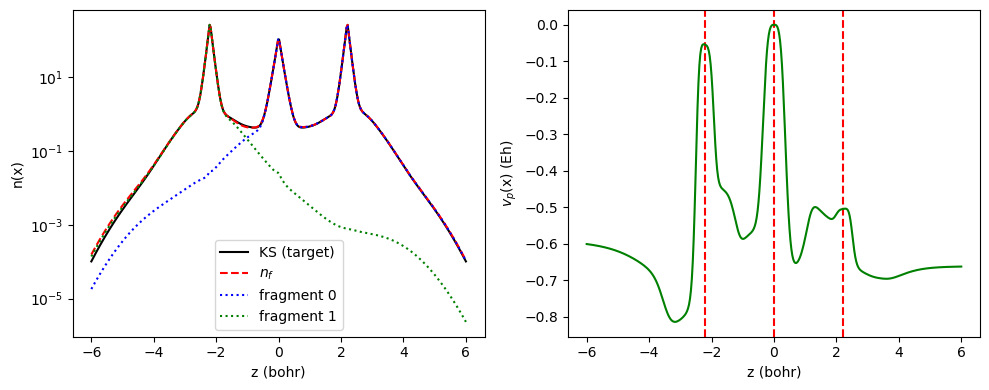

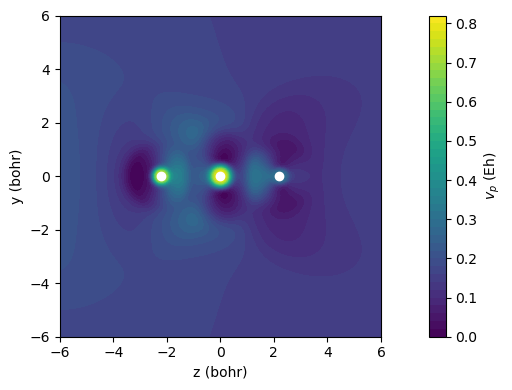

In [7]:
# # 1D plot along molecular axis
x = np.linspace(-6, 6, 400)
line = np.column_stack([np.zeros_like(x), np.zeros_like(x), x])
n_f = mf3.eval_density(line)                    # promolecular density
n_0 = mf3.eval_density(line, frag=0)            # fragment densities
n_1 = mf3.eval_density(line, frag=1)
vp  = mf3.eval_Vp(line)
n_ks = numint.eval_rho(mol.mol, numint.eval_ao(mol.mol, line), Dref) # target (plain KS) density on the same points
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].semilogy(x, n_ks, 'k-', label='KS (target)')
ax[0].semilogy(x, n_f, 'r--', label='$n_f$')
ax[0].semilogy(x, n_0, 'b:', label='fragment 0')
ax[0].semilogy(x, n_1, 'g:', label='fragment 1')
for Ri in mol.mol.atom_coords(): ax[1].axvline(x=Ri[2], color='r', linestyle='dashed')
ax[0].set_xlabel('z (bohr)'); ax[0].set_ylabel('n(x)'); ax[0].legend()
ax[1].plot(x, vp - vp[len(x) // 2], 'g-')      # Vp is defined up to a constant: fix a reference point
ax[1].set_xlabel('z (bohr)'); ax[1].set_ylabel('$v_p$(x) (Eh)')
fig.tight_layout()
plt.show()

# 2D map of Vp in the xy plane (z = 0)
x = np.linspace(-6, 6, 160); yy = np.linspace(-6, 6, 160)
X, Y = np.meshgrid(x, yy)
pts = np.column_stack([X.ravel() * 0, Y.ravel(), X.ravel()])
V = mf3.eval_Vp(pts).reshape(X.shape)
fig, ax = plt.subplots(figsize=(10, 4))
c = ax.contourf(X, Y, V - V.min(), 40, cmap='viridis'); fig.colorbar(c, label='$v_p$ (Eh)')
for Ri in mol.mol.atom_coords():  ax.plot(Ri[2], Ri[1], 'wo')
ax.set_xlabel('z (bohr)'); ax.set_ylabel('y (bohr)'); ax.set_aspect('equal')
fig.tight_layout()
plt.show()